# Heuristic Ablation on Extended Benchmarks

This notebook compares three strategies on the extended 1D and 2D data sets:

1. **Greedy**: Greedy sensor allocation + greedy decision tree, exactly Algorithm 4.
2. **Greedy + Beam**: Greedy sensor allocation kept fixed, with the decision tree reconstructed by beam search using `B=3`.
3. **Full Heuristic**: Greedy initialization + beam-search tree + allocation refinement using `d in {1,2,3}` sensor-transfer moves.

The ablation isolates how much improvement comes from better tree construction alone versus the full allocation-refinement heuristic. It uses saved extended-result tables and reconstructs only the Greedy+Beam tree scores.

In [5]:
from collections import defaultdict
from pathlib import Path
from statistics import fmean
import importlib
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

import approximate_comparison_analysis
import heuristic
import input_data
import plot_style

approximate_comparison_analysis = importlib.reload(approximate_comparison_analysis)
heuristic = importlib.reload(heuristic)
input_data = importlib.reload(input_data)
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Settings

Use `RUN_SCOPE = "test"` for quick iteration or `RUN_SCOPE = "full"` after the extended comparison has been regenerated with the current full heuristic settings.

In [6]:
RUN_SCOPE = "full"
DATASETS = ("benchmark_1d", "benchmark_2d")
BEAM_WIDTH = 3
MOVE_SIZES = (1, 2, 3)

RESULTS_ROOT = PROJECT_DIRECTORY / "results" / "cmp_extended"
INPUT_ROOT = PROJECT_DIRECTORY / "inputs"
OUTPUT_DIRECTORY = RESULTS_ROOT / f"summary_heuristic_ablation_{RUN_SCOPE}" / "figures"
SAVE_FIGURES = True

print("Run scope:", RUN_SCOPE)
print("Extended results root:", RESULTS_ROOT)
print("Input root:", INPUT_ROOT)
print("Beam width for Greedy + Beam:", BEAM_WIDTH)
print("Full heuristic move sizes:", MOVE_SIZES)
print("Save figures:", SAVE_FIGURES)


Run scope: full
Extended results root: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended
Input root: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/inputs
Beam width for Greedy + Beam: 3
Full heuristic move sizes: (1, 2, 3)
Save figures: True


In [7]:
METHOD_ORDER = ("Greedy", "Greedy + Beam", "Full Heuristic")
METHOD_STYLES = {
    "Greedy": {"color": plot_style.METHOD_COLORS["Greedy"], "linestyle": plot_style.METHOD_LINESTYLES["Greedy"], "marker": plot_style.METHOD_MARKERS["Greedy"]},
    "Greedy + Beam": {"color": plot_style.METHOD_COLORS["Optimal"], "linestyle": plot_style.METHOD_LINESTYLES["Optimal"], "marker": plot_style.METHOD_MARKERS["Optimal"]},
    "Full Heuristic": {"color": plot_style.METHOD_COLORS["Heuristic"], "linestyle": plot_style.METHOD_LINESTYLES["Heuristic"], "marker": plot_style.METHOD_MARKERS["Heuristic"]},
}


def load_extended_records(dataset):
    return approximate_comparison_analysis.load_approximate_results(
        dataset,
        results_root=RESULTS_ROOT,
        run_scope=RUN_SCOPE,
    )


def greedy_beam_error(record):
    K = int(record["K"])
    M = int(record["M"])
    pairs = tuple((i, j) for i in range(K) for j in range(i + 1, K))
    _, _, _, pair_error_table = input_data.load_sparse_input(
        INPUT_ROOT / str(record["dataset"]) / f"{record['case']}.csv"
    )
    allocation = tuple(int(value) for value in record["greedy_allocation"])
    pair_locations, pair_errors = heuristic._compute_pair_errors(
        pairs,
        M,
        allocation,
        pair_error_table,
    )
    tree = heuristic._build_tree_with_beam_search(
        K,
        pair_locations,
        pair_errors,
        BEAM_WIDTH,
    )
    return heuristic._tree_error(tree, K)


def build_ablation_records(records_by_dataset):
    ablation_records = []
    for dataset, records in records_by_dataset.items():
        display(Markdown(f"### Reconstructing Greedy + Beam for `{dataset}`"))
        for index, record in enumerate(records, start=1):
            greedy_beam = greedy_beam_error(record)
            ablation_records.append({
                "dataset": dataset,
                "case": str(record["case"]),
                "field_model": str(record["field_model"]),
                "dimension": int(record["spatial_dimension"]),
                "K": int(record["K"]),
                "M": int(record["M"]),
                "budget_level": int(record["budget_level"]),
                "budget_ratio": float(record["budget_fraction_of_N_min"]),
                "Greedy": float(record["greedy_error"]),
                "Greedy + Beam": greedy_beam,
                "Full Heuristic": float(record["heuristic_error"]),
            })
            if index == 1 or index % 100 == 0 or index == len(records):
                print(f"{dataset}: reconstructed {index}/{len(records)}")
    return ablation_records


def mean_by_budget(records):
    rows = []
    for dimension in sorted({record["dimension"] for record in records}):
        dimension_records = [record for record in records if record["dimension"] == dimension]
        for budget_level in sorted({record["budget_level"] for record in dimension_records}):
            selected = [record for record in dimension_records if record["budget_level"] == budget_level]
            row = {
                "dimension": f"{dimension}D",
                "budget_level": budget_level,
                "budget_ratio": fmean(record["budget_ratio"] for record in selected),
                "runs": len(selected),
            }
            for method in METHOD_ORDER:
                row[method] = fmean(record[method] for record in selected)
            row["beam_improvement_vs_greedy"] = row["Greedy"] - row["Greedy + Beam"]
            row["full_improvement_vs_greedy"] = row["Greedy"] - row["Full Heuristic"]
            row["allocation_refinement_gain"] = row["Greedy + Beam"] - row["Full Heuristic"]
            rows.append(row)
    return rows


def overall_summary(records):
    rows = []
    for dimension in sorted({record["dimension"] for record in records}):
        selected = [record for record in records if record["dimension"] == dimension]
        greedy = fmean(record["Greedy"] for record in selected)
        greedy_beam = fmean(record["Greedy + Beam"] for record in selected)
        full = fmean(record["Full Heuristic"] for record in selected)
        rows.append({
            "dimension": f"{dimension}D",
            "runs": len(selected),
            "Greedy": greedy,
            "Greedy + Beam": greedy_beam,
            "Full Heuristic": full,
            "beam_improvement_vs_greedy": greedy - greedy_beam,
            "full_improvement_vs_greedy": greedy - full,
            "allocation_refinement_gain": greedy_beam - full,
        })
    return rows


def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if key in formats else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            values.append(formatter(row[key]) if formatter else str(row[key]))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])


In [8]:
records_by_dataset = {dataset: load_extended_records(dataset) for dataset in DATASETS}
ablation_records = build_ablation_records(records_by_dataset)

summary_rows = overall_summary(ablation_records)
budget_rows = mean_by_budget(ablation_records)

display(Markdown("### Overall Ablation Summary"))
display(Markdown(markdown_table(
    summary_rows,
    (
        ("Dimension", "dimension"),
        ("Runs", "runs"),
        ("Greedy", "Greedy"),
        ("Greedy + Beam", "Greedy + Beam"),
        ("Full Heuristic", "Full Heuristic"),
        ("Beam gain", "beam_improvement_vs_greedy"),
        ("Full gain", "full_improvement_vs_greedy"),
        ("Allocation-refinement gain", "allocation_refinement_gain"),
    ),
    {
        "runs": lambda value: f"{int(value)}",
        "Greedy": lambda value: f"{value:.5f}",
        "Greedy + Beam": lambda value: f"{value:.5f}",
        "Full Heuristic": lambda value: f"{value:.5f}",
        "beam_improvement_vs_greedy": lambda value: f"{value:.5f}",
        "full_improvement_vs_greedy": lambda value: f"{value:.5f}",
        "allocation_refinement_gain": lambda value: f"{value:.5f}",
    },
)))

display(Markdown("### Ablation Summary by Budget"))
display(Markdown(markdown_table(
    budget_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Runs", "runs"),
        ("Greedy", "Greedy"),
        ("Greedy + Beam", "Greedy + Beam"),
        ("Full Heuristic", "Full Heuristic"),
        ("Beam gain", "beam_improvement_vs_greedy"),
        ("Allocation-refinement gain", "allocation_refinement_gain"),
    ),
    {
        "budget_level": lambda value: f"{int(value)}",
        "budget_ratio": lambda value: f"{value:.3f}",
        "runs": lambda value: f"{int(value)}",
        "Greedy": lambda value: f"{value:.5f}",
        "Greedy + Beam": lambda value: f"{value:.5f}",
        "Full Heuristic": lambda value: f"{value:.5f}",
        "beam_improvement_vs_greedy": lambda value: f"{value:.5f}",
        "allocation_refinement_gain": lambda value: f"{value:.5f}",
    },
)))


### Reconstructing Greedy + Beam for `benchmark_1d`

benchmark_1d: reconstructed 1/10728
benchmark_1d: reconstructed 100/10728
benchmark_1d: reconstructed 200/10728
benchmark_1d: reconstructed 300/10728
benchmark_1d: reconstructed 400/10728
benchmark_1d: reconstructed 500/10728
benchmark_1d: reconstructed 600/10728
benchmark_1d: reconstructed 700/10728
benchmark_1d: reconstructed 800/10728
benchmark_1d: reconstructed 900/10728
benchmark_1d: reconstructed 1000/10728
benchmark_1d: reconstructed 1100/10728
benchmark_1d: reconstructed 1200/10728
benchmark_1d: reconstructed 1300/10728
benchmark_1d: reconstructed 1400/10728
benchmark_1d: reconstructed 1500/10728
benchmark_1d: reconstructed 1600/10728
benchmark_1d: reconstructed 1700/10728
benchmark_1d: reconstructed 1800/10728
benchmark_1d: reconstructed 1900/10728
benchmark_1d: reconstructed 2000/10728
benchmark_1d: reconstructed 2100/10728
benchmark_1d: reconstructed 2200/10728
benchmark_1d: reconstructed 2300/10728
benchmark_1d: reconstructed 2400/10728
benchmark_1d: reconstructed 2500/1072

### Reconstructing Greedy + Beam for `benchmark_2d`

benchmark_2d: reconstructed 1/10732
benchmark_2d: reconstructed 100/10732
benchmark_2d: reconstructed 200/10732
benchmark_2d: reconstructed 300/10732
benchmark_2d: reconstructed 400/10732
benchmark_2d: reconstructed 500/10732
benchmark_2d: reconstructed 600/10732
benchmark_2d: reconstructed 700/10732
benchmark_2d: reconstructed 800/10732
benchmark_2d: reconstructed 900/10732
benchmark_2d: reconstructed 1000/10732
benchmark_2d: reconstructed 1100/10732
benchmark_2d: reconstructed 1200/10732
benchmark_2d: reconstructed 1300/10732
benchmark_2d: reconstructed 1400/10732
benchmark_2d: reconstructed 1500/10732
benchmark_2d: reconstructed 1600/10732
benchmark_2d: reconstructed 1700/10732
benchmark_2d: reconstructed 1800/10732
benchmark_2d: reconstructed 1900/10732
benchmark_2d: reconstructed 2000/10732
benchmark_2d: reconstructed 2100/10732
benchmark_2d: reconstructed 2200/10732
benchmark_2d: reconstructed 2300/10732
benchmark_2d: reconstructed 2400/10732
benchmark_2d: reconstructed 2500/1073

### Overall Ablation Summary

| Dimension | Runs | Greedy | Greedy + Beam | Full Heuristic | Beam gain | Full gain | Allocation-refinement gain |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 10728 | 0.18594 | 0.16268 | 0.15582 | 0.02326 | 0.03012 | 0.00685 |
| 2D | 10732 | 0.21706 | 0.19286 | 0.18663 | 0.02420 | 0.03043 | 0.00623 |

### Ablation Summary by Budget

| Dimension | Budget level | Budget ratio | Runs | Greedy | Greedy + Beam | Full Heuristic | Beam gain | Allocation-refinement gain |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 2700 | 0.36852 | 0.32371 | 0.32165 | 0.04480 | 0.00206 |
| 1D | 2 | 0.315 | 2700 | 0.18734 | 0.16395 | 0.15749 | 0.02339 | 0.00646 |
| 1D | 3 | 0.471 | 2692 | 0.10955 | 0.09531 | 0.08584 | 0.01425 | 0.00946 |
| 1D | 4 | 0.602 | 2636 | 0.07551 | 0.06523 | 0.05573 | 0.01028 | 0.00950 |
| 2D | 1 | 0.159 | 2700 | 0.40612 | 0.36242 | 0.36084 | 0.04370 | 0.00158 |
| 2D | 2 | 0.297 | 2700 | 0.22318 | 0.19842 | 0.19211 | 0.02476 | 0.00632 |
| 2D | 3 | 0.444 | 2695 | 0.13747 | 0.12133 | 0.11306 | 0.01615 | 0.00826 |
| 2D | 4 | 0.564 | 2637 | 0.09856 | 0.08668 | 0.07785 | 0.01188 | 0.00883 |

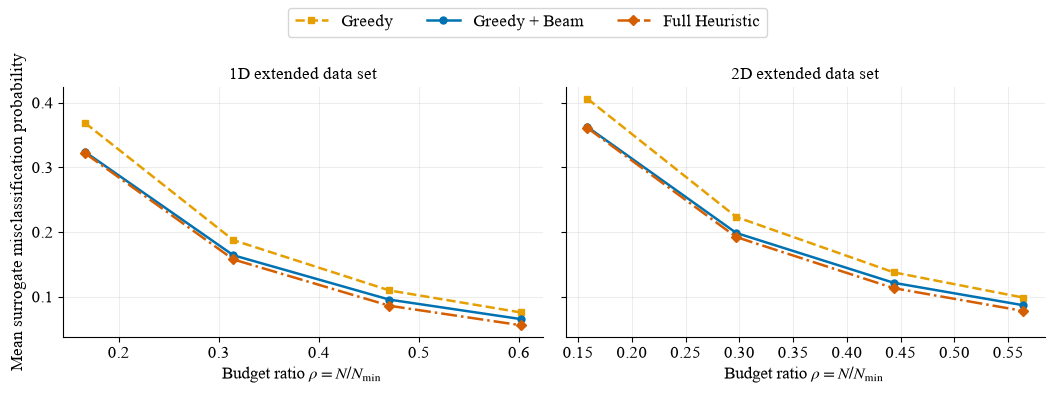

Saved figures under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended/summary_heuristic_ablation_full/figures


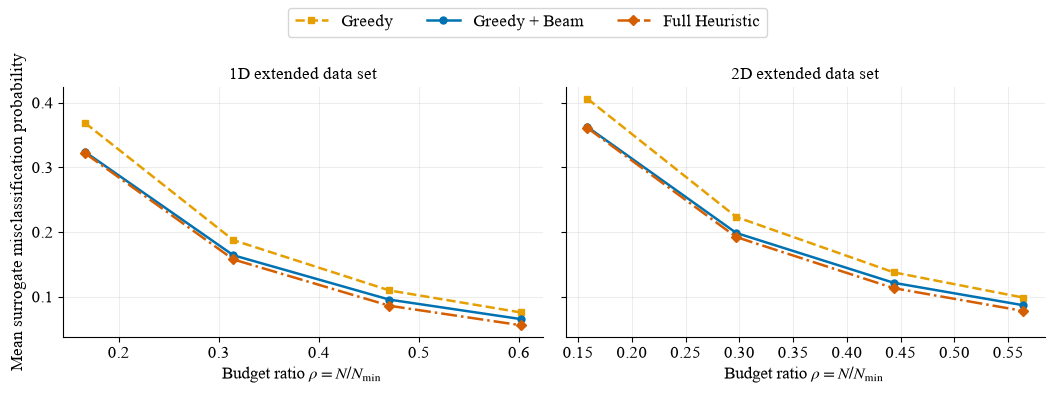

In [9]:
def plot_ablation_curves(rows):
    dimensions = sorted({row["dimension"] for row in rows})
    figure, axes = plt.subplots(1, len(dimensions), figsize=(10.8, 4.0), sharey=True)
    if len(dimensions) == 1:
        axes = [axes]
    for axis, dimension in zip(axes, dimensions):
        selected = [row for row in rows if row["dimension"] == dimension]
        for method in METHOD_ORDER:
            style = METHOD_STYLES[method]
            axis.plot(
                [row["budget_ratio"] for row in selected],
                [row[method] for row in selected],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=method,
            )
        axis.set_title(f"{dimension} extended data set")
        axis.set_xlabel(r"Budget ratio $\rho=N/N_{\min}$")
        axis.grid(alpha=0.22, linewidth=0.8)
        axis.set_axisbelow(True)
    axes[0].set_ylabel("Mean surrogate misclassification probability")
    handles, labels = axes[-1].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper center", ncol=len(labels))
    figure.tight_layout(rect=(0, 0, 1, 0.88))
    return figure


figure = plot_ablation_curves(budget_rows)
display(figure)

if SAVE_FIGURES:
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    figure.savefig(OUTPUT_DIRECTORY / "heuristic_ablation_extended.png", dpi=600, bbox_inches="tight")
    figure.savefig(OUTPUT_DIRECTORY / "heuristic_ablation_extended.pdf", bbox_inches="tight")
    print("Saved figures under:", OUTPUT_DIRECTORY)


## Saved Files

When `SAVE_FIGURES = True`, this notebook writes:

```text
results/cmp_extended/summary_heuristic_ablation_<test|full>/figures/
├── heuristic_ablation_extended.pdf
└── heuristic_ablation_extended.png
```